In [4]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from io import BytesIO
from tqdm.notebook import tqdm
import cv2

import common

In [17]:
def read_pbtxt_to_dict(pbtxt_file):
    data_dict = {}
    with open(pbtxt_file, 'r') as file:
        item_dict = {}
        for line in file:
            line = line.strip()
            if line.startswith("item {"):
                item_dict = {}
            elif line.startswith("}"):
                data_dict[item_dict['id']] = item_dict['display_name']
            else:
                key, value = line.split(':', 1)
                item_dict[key.strip()] = value.strip().strip('"')
    return data_dict

# Replace 'your_pbtxt_file_path.pbtxt' with the path to your pbtxt file
pbtxt_file_path = 'data/label_map.pbtxt'
result_dict = read_pbtxt_to_dict(pbtxt_file_path)
print(result_dict)

{'1': 'person', '2': 'chair', '3': 'table', '4': 'armchair', '5': 'tv', '6': 'wheeled walker'}


In [9]:
ds = common.load_dataset("data/training_25k_sample_4_mask.tfrecord", common.parse_feature_masks)

In [10]:
for example in ds:
    img_string = (example['image/encoded'].numpy())
    pil_img = Image.open(BytesIO(img_string))
    img  = np.array(pil_img)
    
    img_string = (example['image/encoded_categories'].numpy())
    pil_img = Image.open(BytesIO(img_string))
    img_cat  = np.array(pil_img)
    break

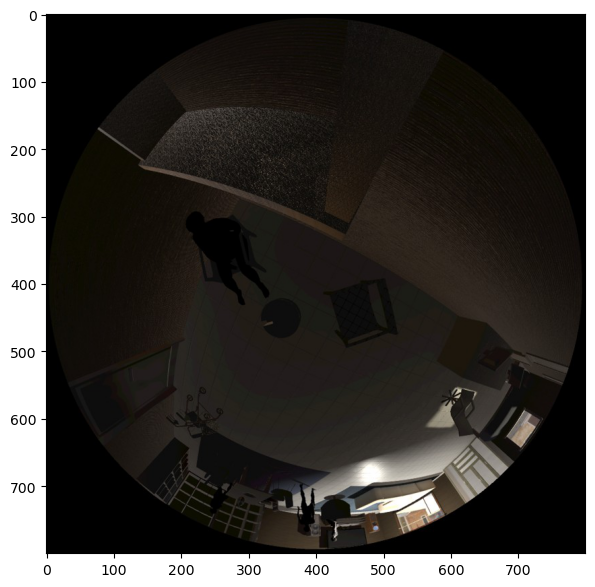

In [24]:
plt.figure(figsize=(7, 7))
plt.imshow(img)

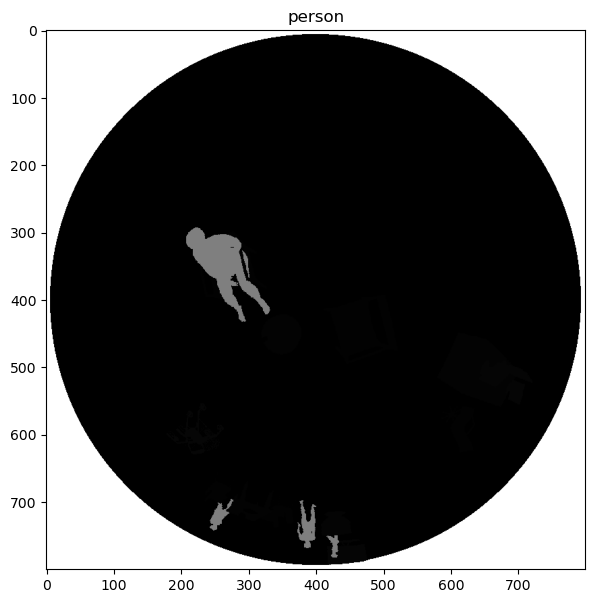

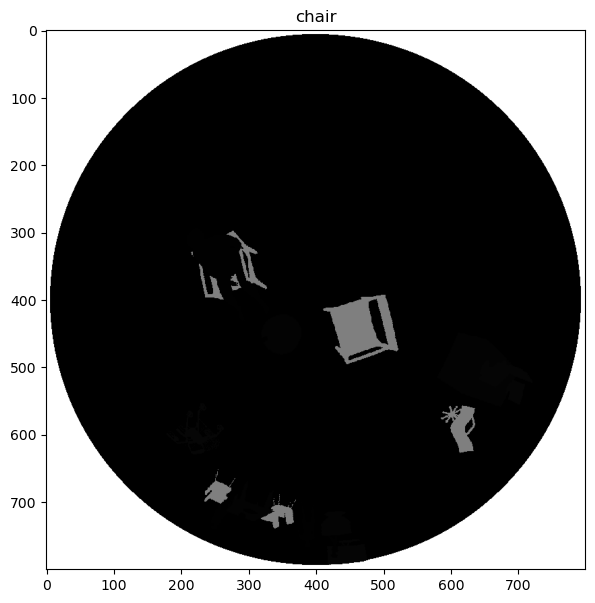

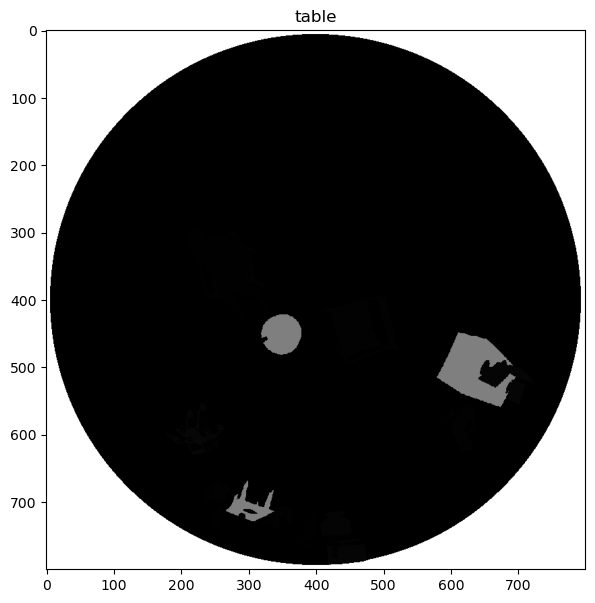

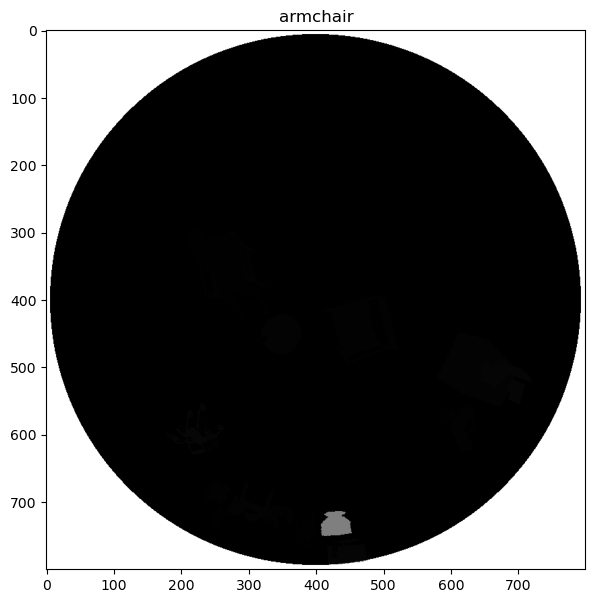

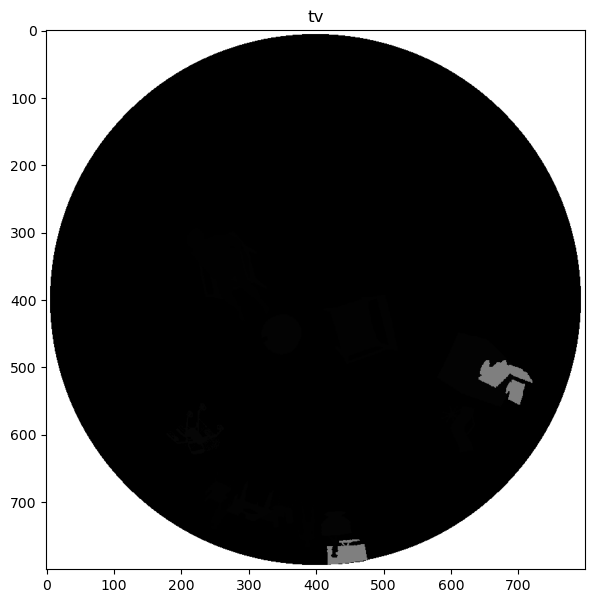

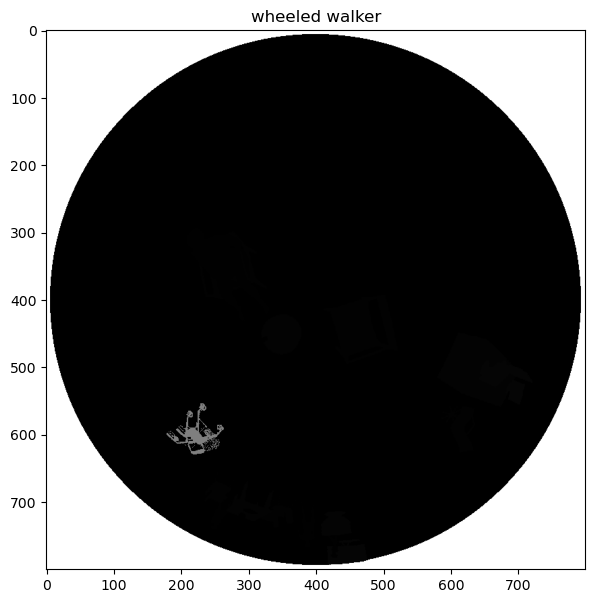

In [23]:
unique_pxl_values = np.unique(img_cat)
for val in unique_pxl_values:
    if str(val) not in result_dict:
        continue
    
    tmp = img.copy()
    tmp = img_cat.copy()
    tmp[tmp == val] = 127
    plt.figure(figsize=(7, 7))
    plt.title(result_dict[str(val)])
    plt.imshow(tmp, cmap="gray")
    